In [1]:
from fktools import *
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator

In [2]:
from fktools import *
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator

def control_add_one(position_qubits: int) -> QuantumCircuit:
    qc = QuantumCircuit(position_qubits + 1, name='control_add_one')

    for i in range(position_qubits, 0, -1):
        qc.mcx([j for j in range(i)], i)
    
    return qc

class walk_circuit_simpler:
    def __init__(self, 
                 nodes_power: int, 
                 num_steps: int, 
                 start_bits:str | None = None, 
                 start_phases: list | None = None, 
                 coin_phase: int = 0,
                 use_phase_defect: bool = False, 
                 defect_step: int | None = None, 
                 defect_qubit: int | None = None, 
                 defect_strength: float | None = None):
        
        self.nodes_power = nodes_power
        self.num_steps = num_steps

        self.coin_phase = coin_phase

        self.use_phase_defect = use_phase_defect
        self.defect_step = defect_step
        self.defect_qubit = defect_qubit
        self.defect_strength = defect_strength

        if start_bits is not None:
            self.start_bits = list(reversed(start_bits))
            assert len(self.start_bits) == self.nodes_power, f"length of start_bits must be the same as nodes_power, got: {len(self.start_bits)} expected: {self.nodes_power}"
        else:
            self.start_bits = "0" * self.nodes_power

        if start_phases is not None:
            self.start_phases = list(reversed(start_phases))
            assert len(self.start_phases) == self.nodes_power, f"length of start_phases must be the same as nodes_power, got: {len(self.start_phases)} expected: {self.nodes_power}"
        else:
            self.start_phases = [0] * 2**self.nodes_power

    def build(self) -> QuantumCircuit:
        q_pos = QuantumRegister(self.nodes_power, "q_pos")
        q_coin = QuantumRegister(1, "q_coin")
        c_pos = ClassicalRegister(self.nodes_power, "c_pos")
        regs = [q_pos, q_coin, c_pos]

        qc = QuantumCircuit(*regs)

        # setting start state
        for i, bit in enumerate(self.start_bits):
            if bit == "1":
                qc.x(q_pos[i])
            
            # qc.p(self.start_phases[i], q_pos[i])

        # coin initialization
        qc.h(q_coin)
        qc.p(self.coin_phase, q_coin)

        for step in range(self.num_steps):
            # coin
            qc.h(q_coin)


            # defect
            if self.use_phase_defect and self.defect_step is not None and self.defect_qubit is not None and self.defect_strength is not None:
                if step == self.defect_step:
                    qc.p(self.defect_strength, self.defect_qubit)


            # shift right for coin |1>
            qc.append(control_add_one(self.nodes_power), [q_coin, *q_pos])
            
            # shift left for coin |0>
            qc.x(q_coin)
            qc.x(q_pos)
            qc.append(control_add_one(self.nodes_power), [q_coin, *q_pos])
            qc.x(q_coin)
            qc.x(q_pos)


        qc.measure(q_pos, c_pos)

        self.qc = qc

        return qc
    
    def run(self, simulator = AerSimulator(), shots = 1024):

        tcirc = transpile(self.qc, simulator)

        result = simulator.run(tcirc, shots=shots).result()
        counts = result.get_counts(0)

        probs = np.zeros(shape=(2**self.nodes_power), dtype=np.float32)

        for key in counts.keys():
            probs[int(key, 2)] = counts[key]
        probs /= np.sum(probs)

        return probs

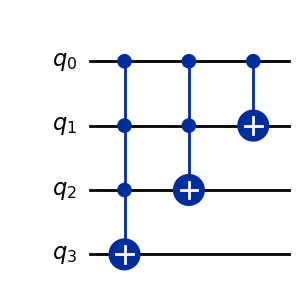

In [3]:
control_add_one(3).draw('mpl')

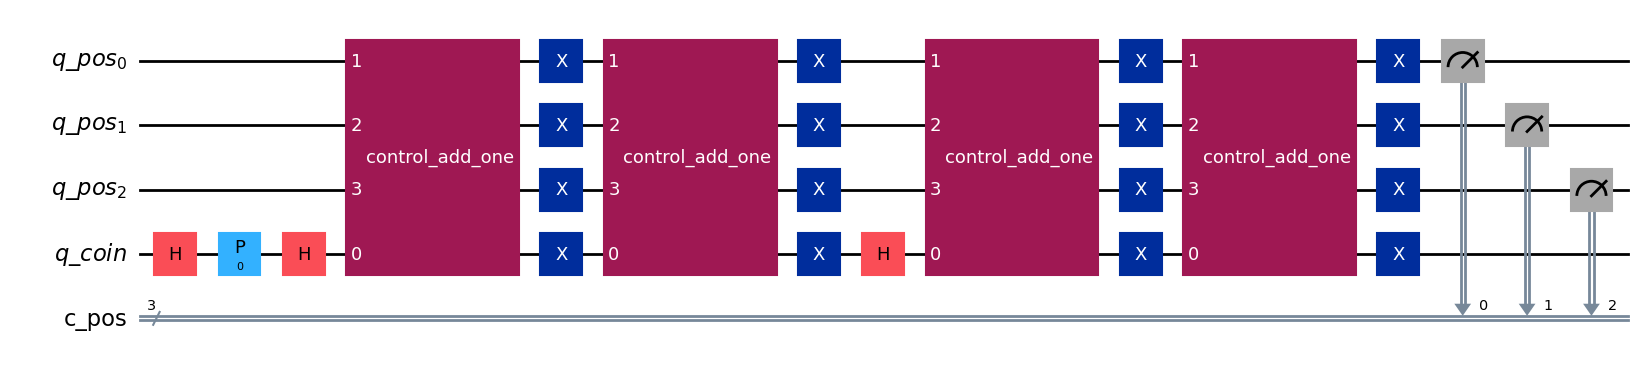

In [5]:
wcs = walk_circuit_simpler(3, 2)

wcs.build().draw('mpl')